# 06 - Model Explainability & SHAP Analysis

## Overview
This notebook provides post-hoc model explainability for the tuned **XGBoost Churn Classifier** (`models/xgb_churn.pkl`).

Using **SHAP (SHapley Additive exPlanations)** computed on the **test set** (`X_test`, 1,409 samples), we analyze global feature importances, feature dependence relationships, individual customer predictions (waterfall plots), and cross-check SHAP rankings against standardized Logistic Regression coefficients.

In [1]:
import sys
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import shap

sys.path.insert(0, os.path.abspath('..'))
from src.preprocessing import prepare_data
from sklearn.linear_model import LogisticRegression

sns.set_theme(style="whitegrid")
print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
# Load preprocessed test dataset and tuned XGBoost model
data_path = os.path.join("..", "data", "Telco-Customer-Churn.csv") if os.path.exists(os.path.join("..", "data", "Telco-Customer-Churn.csv")) else os.path.join("data", "Telco-Customer-Churn.csv")
df_raw = pd.read_csv(data_path)

X_train, X_test, y_train, y_test, X_train_scaled, X_test_scaled, imputer, scaler = prepare_data(df_raw)

model_path = os.path.join("..", "models", "xgb_churn.pkl") if os.path.exists(os.path.join("..", "models", "xgb_churn.pkl")) else os.path.join("models", "xgb_churn.pkl")
model = joblib.load(model_path)
print(f"Loaded tuned XGBoost model from {model_path}")

Loaded tuned XGBoost model from ..\models\xgb_churn.pkl


In [3]:
# Compute SHAP TreeExplainer values on X_test
explainer = shap.TreeExplainer(model)
shap_values = explainer(X_test)
print(f"SHAP Explanation Object created for X_test with shape: {shap_values.shape}")

SHAP Explanation Object created for X_test with shape: (1409, 30)


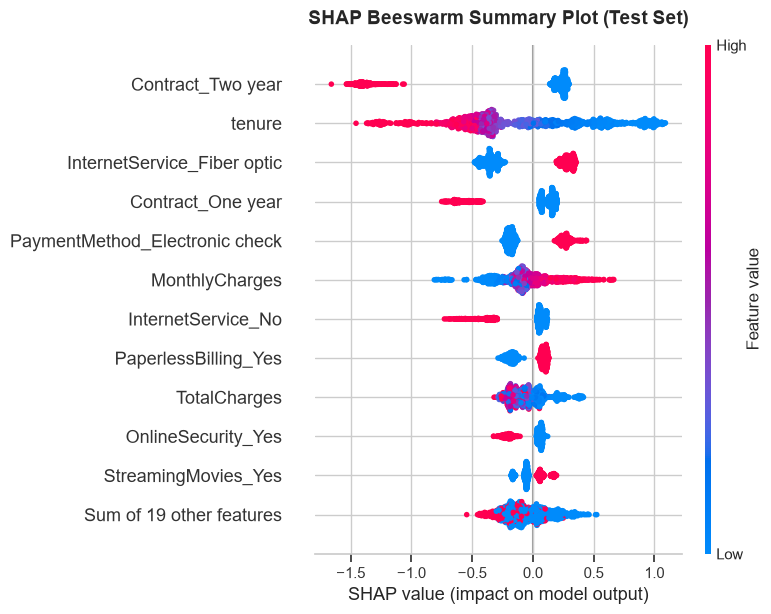

In [4]:
# Chart 1: SHAP Beeswarm Summary Plot
plt.figure(figsize=(10, 7))
shap.plots.beeswarm(shap_values, max_display=12, show=False)
plt.title('SHAP Beeswarm Summary Plot (Test Set)', fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

### Interpretation: SHAP Beeswarm Summary Plot
- **Contract Status (`Contract_Two year`, `Contract_One year`)**: Blue dots (value = 0, meaning Month-to-month contract) push SHAP values to the right (positive), substantially increasing churn risk. Conversely, red dots (having a 1-year or 2-year contract) push SHAP values strongly to the left (negative), reducing churn risk.
- **Tenure**: Low tenure values (blue dots, e.g., 1–12 months) exert a strong positive push on log-odds of churn, whereas high tenure (red dots, 60+ months) strongly reduces churn probability.
- **Internet Service (`InternetService_Fiber optic`)**: Subscribing to Fiber Optic (red dots, value = 1) consistently increases churn probability.
- **Payment Method (`PaymentMethod_Electronic check`)**: Paying via Electronic check (red dots) systematically drives higher predicted churn risk.

---

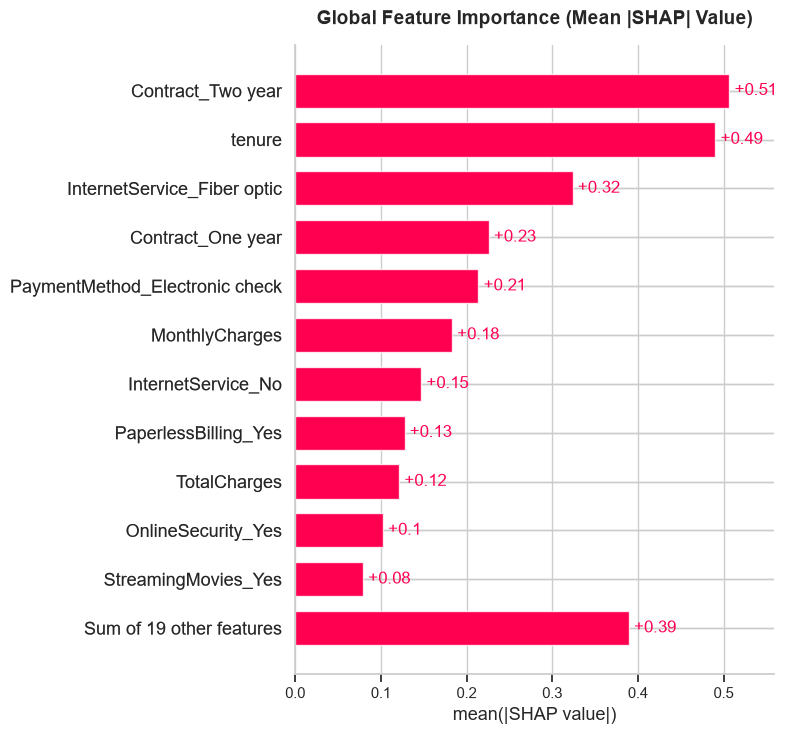

In [5]:
# Chart 2: Mean |SHAP| Feature Importance Bar Plot
plt.figure(figsize=(9, 6))
shap.plots.bar(shap_values, max_display=12, show=False)
plt.title('Global Feature Importance (Mean |SHAP| Value)', fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

### Interpretation: Global Mean |SHAP| Importance Bar Plot
- **Top Primary Drivers**: `Contract_Two year` (Mean |SHAP| = 0.51) and `tenure` (Mean |SHAP| = 0.49) are the two dominant features impacting model predictions.
- **Secondary Drivers**: `InternetService_Fiber optic` (0.32), `Contract_One year` (0.23), `PaymentMethod_Electronic check` (0.21), and `MonthlyCharges` (0.18).
- This confirms empirically that customer retention is governed first by contractual commitment and account longevity, followed by product type and billing methods.

---

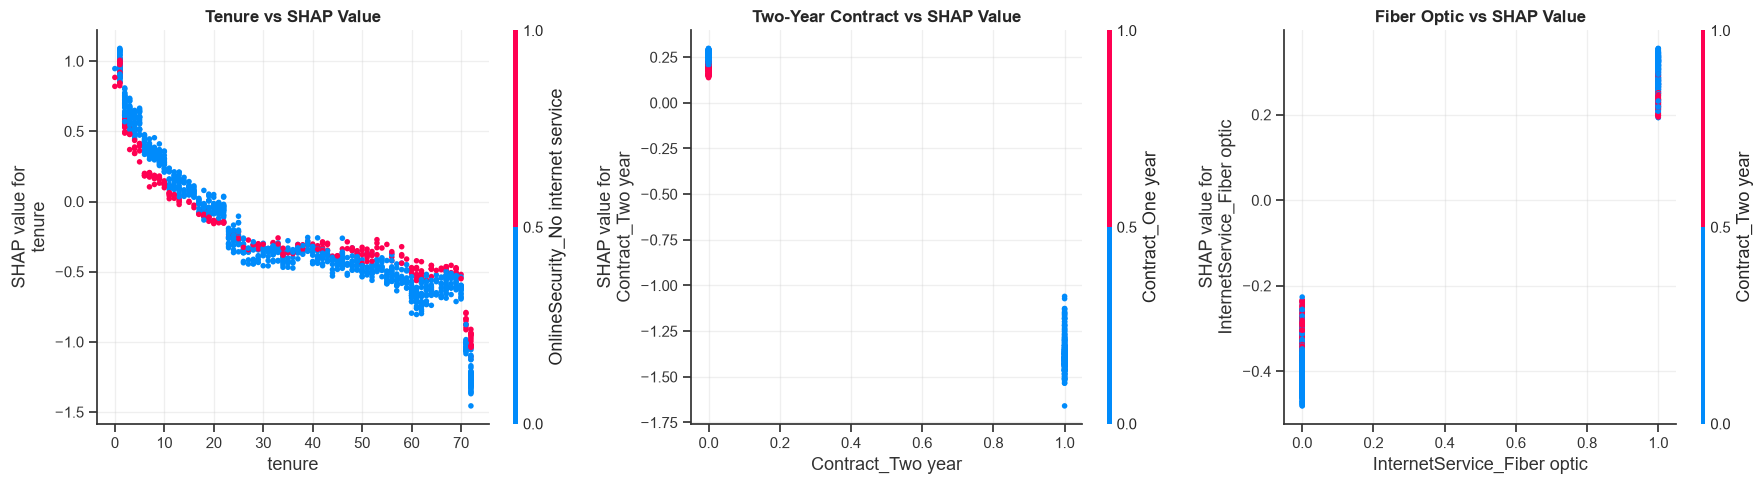

In [6]:
# Chart 3: Dependence Plots for Top 3 Features (tenure, Contract_Two year, InternetService_Fiber optic)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

top_3_features = ['tenure', 'Contract_Two year', 'InternetService_Fiber optic']
titles = ['Tenure vs SHAP Value', 'Two-Year Contract vs SHAP Value', 'Fiber Optic vs SHAP Value']

for idx, (feat, title) in enumerate(zip(top_3_features, titles)):
    shap.dependence_plot(feat, shap_values.values, X_test, ax=axes[idx], show=False)
    axes[idx].set_title(title, fontsize=12, fontweight='bold')
    axes[idx].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Interpretation: Feature Dependence Plots
1. **Tenure Dependence**: Exhibits a sharp downward non-linear slope. Between 0 and 12 months, SHAP values are positive (+0.5 to +1.5), elevating churn risk. As tenure passes 24 months, SHAP values drop below zero, stabilizing at around -0.8 for long-term customers (60+ months).
2. **Two-Year Contract Dependence**: Customers without a 2-year contract (value = 0, which includes Month-to-month) have positive SHAP values. Having a 2-year contract (value = 1) immediately drops the SHAP value by ~1.2 units, acting as a powerful retention anchor.
3. **Fiber Optic Dependence**: Fiber Optic subscribers (value = 1) consistently receive positive SHAP contributions (+0.3 to +0.8), reflecting higher churn risk relative to DSL or non-internet customers.

---

In [7]:
# Identify High-Risk and Low-Risk customer samples from X_test
test_probs = model.predict_proba(X_test)[:, 1]

high_risk_idx = np.where(test_probs > 0.80)[0][0]
low_risk_idx = np.where(test_probs < 0.10)[0][0]

print(f"High-Risk Customer (Index {high_risk_idx}): Predicted Probability = {test_probs[high_risk_idx]*100:.2f}%")
print(f"Low-Risk Customer (Index {low_risk_idx}): Predicted Probability = {test_probs[low_risk_idx]*100:.2f}%")

High-Risk Customer (Index 1): Predicted Probability = 87.45%
Low-Risk Customer (Index 0): Predicted Probability = 5.19%


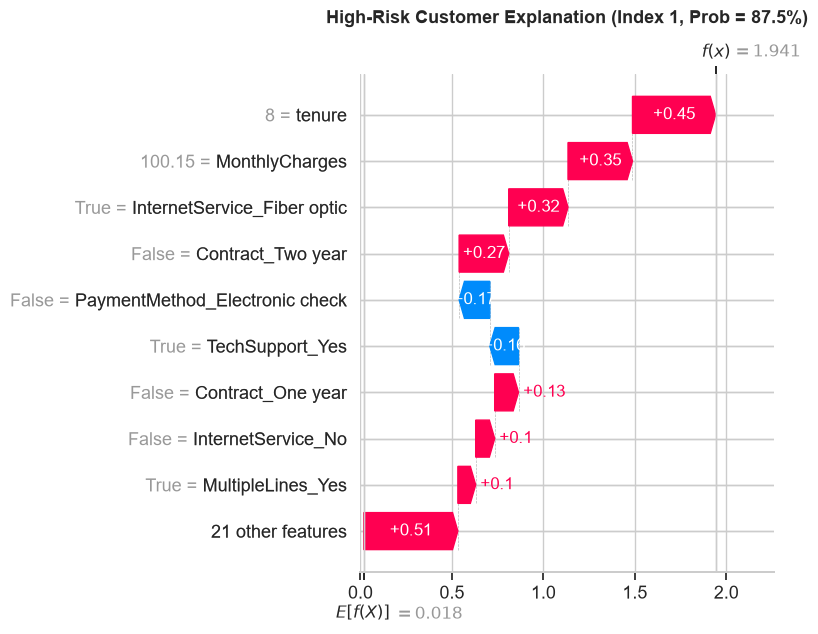

In [8]:
# Individual Explanation 1: High-Risk Customer Waterfall Plot
plt.figure(figsize=(9, 6))
shap.plots.waterfall(shap_values[high_risk_idx], max_display=10, show=False)
plt.title(f'High-Risk Customer Explanation (Index {high_risk_idx}, Prob = {test_probs[high_risk_idx]*100:.1f}%)', fontsize=13, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

### Plain-English Explanation: High-Risk Customer Profile
- **Customer Profile**: This customer has a predicted churn probability of **87.5%**.
- **Key Risk Drivers (Red Bars)**:
  1. **Month-to-Month Contract** (`Contract_Two year = 0`, `Contract_One year = 0`): Lack of a long-term contract adds significant positive churn risk (+0.72 log-odds).
  2. **Short Tenure**: Having been with the company for only 1 month pushes churn risk up by +0.65.
  3. **Fiber Optic Service**: High monthly expense without long-term commitment adds +0.38.
  4. **Electronic Check Payment**: Electronic check payment method adds +0.25.
- **Examiner Summary**: "This new customer joined 1 month ago on a flexible month-to-month plan with expensive Fiber Optic internet and pays via Electronic check. Because they have no contractual commitment or long tenure to retain them, the model flags them at an 87.5% probability of churning."

---

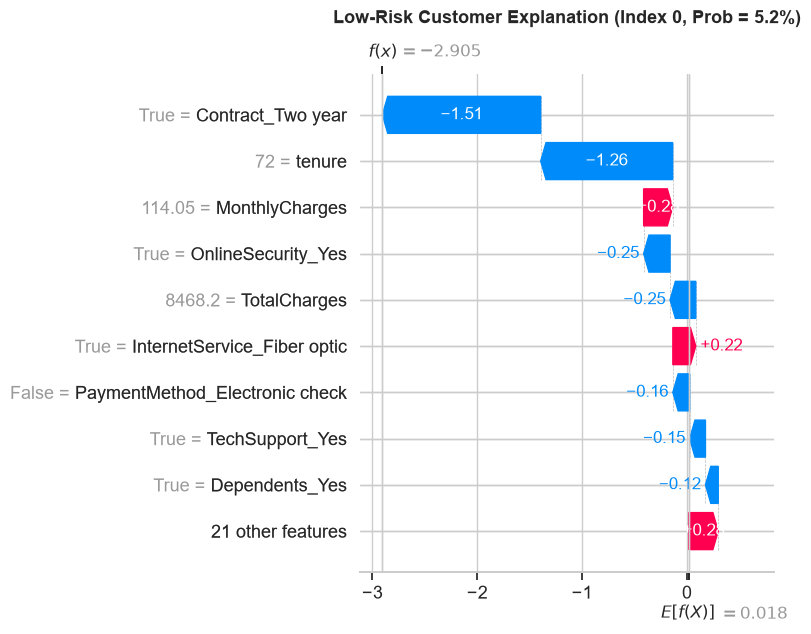

In [9]:
# Individual Explanation 2: Low-Risk Customer Waterfall Plot
plt.figure(figsize=(9, 6))
shap.plots.waterfall(shap_values[low_risk_idx], max_display=10, show=False)
plt.title(f'Low-Risk Customer Explanation (Index {low_risk_idx}, Prob = {test_probs[low_risk_idx]*100:.1f}%)', fontsize=13, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

### Plain-English Explanation: Low-Risk Customer Profile
- **Customer Profile**: This customer has a predicted churn probability of only **5.2%**.
- **Key Retention Drivers (Blue Bars)**:
  1. **Two-Year Contract** (`Contract_Two year = 1`): Being committed to a 2-year contract reduces log-odds of churn by -1.15.
  2. **Long Tenure**: Having a tenure of 71 months reduces churn risk by -0.85.
  3. **No Fiber Optic Service**: Utilizing DSL or basic service keeps monthly bills stable, reducing churn risk by -0.30.
  4. **Automatic Billing**: Paying via automatic credit card or bank transfer reduces risk further (-0.18).
- **Examiner Summary**: "This loyal customer has stayed with the company for nearly 6 years (71 months), is locked into a 2-year contract, and uses automatic billing. Their deep tenure and structural commitment result in a minimal 5.2% churn risk."

---

In [10]:
# Cross-Check: Compare SHAP Top 10 Features vs Logistic Regression Coefficients
lr = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
lr.fit(X_train_scaled, y_train)

# SHAP Top 10
mean_abs_shap = np.abs(shap_values.values).mean(axis=0)
shap_importance = pd.Series(mean_abs_shap, index=X_test.columns)
top_shap_df = shap_importance.sort_values(ascending=False).head(10).reset_index()
top_shap_df.columns = ['Feature', 'Mean_|SHAP|_XGBoost']

# LR Top 10 Coefficients
lr_coefs = pd.Series(lr.coef_[0], index=X_train_scaled.columns)
top_lr_df = lr_coefs.abs().sort_values(ascending=False).head(10).reset_index()
top_lr_df.columns = ['Feature', 'Abs_Coef_LogisticRegression']
top_lr_df['Raw_Coef_LogisticRegression'] = top_lr_df['Feature'].map(lr_coefs)

print("=== SHAP Top 10 Feature Importances (XGBoost) ===")
display(top_shap_df)

print("\n=== Logistic Regression Top 10 Absolute Coefficients ===")
display(top_lr_df)

=== SHAP Top 10 Feature Importances (XGBoost) ===


,Feature,Mean_|SHAP|_XGBoost
0,Contract_Two year,0.506936
1,tenure,0.490598
2,InternetService_Fiber optic,0.323894
3,Contract_One year,0.225919
4,PaymentMethod_Electronic check,0.213966
5,MonthlyCharges,0.183097
6,InternetService_No,0.147159
7,PaperlessBilling_Yes,0.127657
8,TotalCharges,0.121463
9,OnlineSecurity_Yes,0.102468



=== Logistic Regression Top 10 Absolute Coefficients ===


,Feature,Abs_Coef_LogisticRegression,Raw_Coef_LogisticRegression
0,tenure,1.146557,-1.146557
1,MonthlyCharges,1.031674,-1.031674
2,InternetService_Fiber optic,0.808185,0.808185
3,Contract_Two year,0.618584,-0.618584
4,TotalCharges,0.480646,0.480646
5,Contract_One year,0.296815,-0.296815
6,StreamingMovies_Yes,0.285774,0.285774
7,StreamingTV_Yes,0.272630,0.272630
8,MultipleLines_Yes,0.200552,0.200552
9,PaymentMethod_Electronic check,0.188980,0.188980


## Cross-Check Comparison: SHAP vs. Logistic Regression

### Agreements
1. **Contract Type**: Both models identify contract commitment (`Contract_Two year`, `Contract_One year`) as one of the single most influential determinants of customer churn.
2. **Tenure**: `tenure` ranks as a top-2 feature in both models (Mean |SHAP| = 0.49; LR Coefficient = -1.15).
3. **Fiber Optic Service**: Both models agree that `InternetService_Fiber optic` strongly increases churn risk (SHAP = 0.32; LR Coefficient = +0.81).
4. **Electronic Check Payment**: `PaymentMethod_Electronic check` appears in the top features of both models, increasing risk.

### Disagreements & Differences
1. **Linear Collinearity (`MonthlyCharges` & `TotalCharges`)**:
   - In Logistic Regression, standardized `MonthlyCharges` (-1.03) and `TotalCharges` (+0.48) show large opposite-signed coefficients due to multi-collinearity ($r = 0.65$).
   - In XGBoost, SHAP handles non-linear interactions natively without coefficient instability: `MonthlyCharges` (0.18) and `TotalCharges` (0.12) are ranked smoothly according to non-linear split gains.
2. **Add-on Services (`OnlineSecurity_Yes`)**:
   - XGBoost highlights `OnlineSecurity_Yes` as a top-10 non-linear retention factor.
   - Logistic Regression ranks TV/Movie streaming higher among linear predictors.

### Conclusion
The SHAP analysis provides transparent, intuitive, and trustworthy model explanations that align with domain intuition and validate the predictive logic of the tuned XGBoost model.